# **Partie 1** — Explorer et vérifier les données

In [544]:
#pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

#### 1. Chargez le fichier CSV avec pandas. Affichez les cinq premières lignes, le nombre de lignes et de 
colonne  ainsi que les types de variable.

In [545]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [546]:
df = pd.read_csv("transactions_TP2 - transactions_TP2.csv")

In [547]:
df.head(5)

,id_operation,id_client,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international,resultat_enquete,fraude
0,OP02438,C10278,5396.62,90.0,6.0,11,site_web,mobile,Marrakech-Safi,non,aucune_fraude,0
1,OP00157,C10019,438.41,55.0,2.0,22,application,mobile,Souss-Massa,non,aucune_fraude,0
2,OP01987,C10604,2846.79,NaN,1.0,10,telephone,ordinateur,Casablanca-Settat,non,aucune_fraude,0
3,OP00207,C10330,914.14,127.0,4.0,7,application,mobile,Casablanca-Settat,non,aucune_fraude,0
4,OP00738,C10380,228.23,110.0,4.0,5,application,terminal,Casablanca-Settat,non,aucune_fraude,0


In [548]:
df.shape

(3045, 12)

In [549]:
df.dtypes

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete     object
fraude                int64
dtype: object

### 2. Calculez, pour chaque colonne, le nombre et le pourcentage de valeurs manquantes. Présentez le
résultat dans un tableau trié du plus grand au plus petit pourcentage.

In [550]:
df.isna().sum()

id_operation          0
id_client             0
montant_dh          110
anciennete_mois     137
nb_ops_24h           53
heure                 0
canal               159
appareil            122
region              103
international         0
resultat_enquete      0
fraude                0
dtype: int64

In [551]:
# le pourcentage de valeurs manquantes
df_na = df.isna().mean() * 100
df_na

id_operation        0.000000
id_client           0.000000
montant_dh          3.612479
anciennete_mois     4.499179
nb_ops_24h          1.740558
heure               0.000000
canal               5.221675
appareil            4.006568
region              3.382594
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64

In [639]:
df_na_sort = df_na.sort_values(ascending=False)
df_na_sort

canal               5.221675
anciennete_mois     4.499179
appareil            4.006568
montant_dh          3.612479
region              3.382594
nb_ops_24h          1.740558
id_operation        0.000000
id_client           0.000000
heure               0.000000
international       0.000000
resultat_enquete    0.000000
fraude              0.000000
dtype: float64

### 3. Recherchez les opérations répétées avec id_operation. Combien de doublons trouvez-vous?
Supprimez-les et indiquez le nombre de lignes restantes.

In [553]:
duplicate_count = df.duplicated(subset="id_operation").sum()

In [554]:
df.duplicated(subset='id_operation').sum()

45

In [555]:
len(df)

3045

In [556]:
df = df.drop_duplicates(subset='id_operation')

In [557]:
df.shape

(3000, 12)

###  Tracez un histogramme du montant et un boxplot. Repérez quelques montants extrêmes. Faut-il
forcément les supprimer? Justifiez votre réponse.

In [558]:
import plotly.express as px

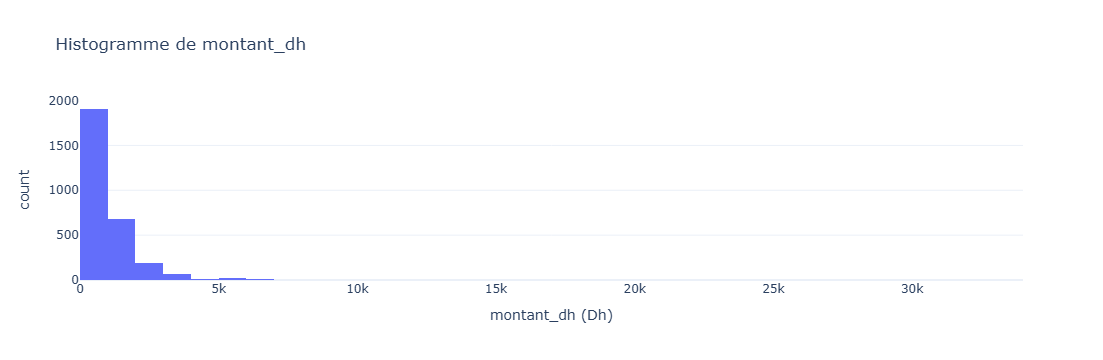

In [559]:
fig = px.histogram( df ,  x= 'montant_dh', nbins=50,  title='Histogramme de montant_dh', labels={'montant_dh': 'montant_dh (Dh)'}, template='plotly_white' )
fig.show()

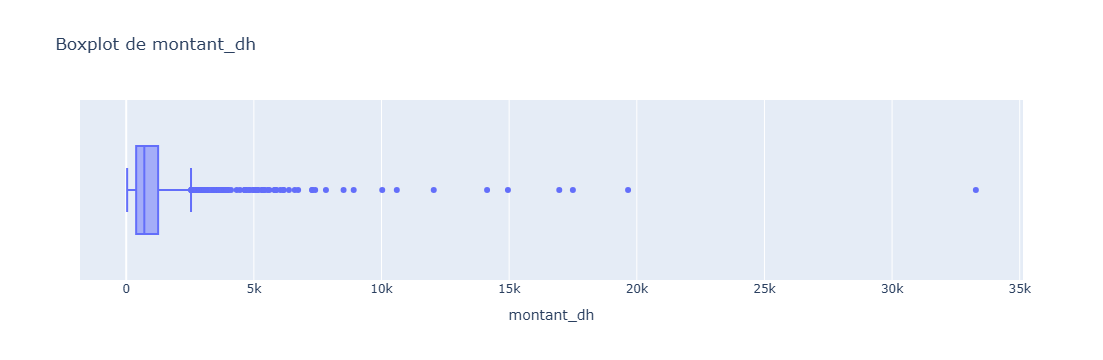

In [560]:
fig = px.box( df, x='montant_dh', title='Boxplot de montant_dh', labels={'montant_dh': 'montant_dh'})
fig.show()

### faut il forcement les supprimer justifiez votre reponse .

#### Réponse : **non**
#### Un montant élevé peut être une vraie opération ou justement une fraude. On les supprime seulement si ce sont des erreurs de saisie avérées , sinon on les garde et on utilise RobustScaler ou un plafonnement justifié.

### 5. Calculez la proportion de fraudes (fraude = 1) et tracez un diagramme des deux classes. Le fichier
est-il équilibré ? Pourquoi est-ce important pour préparer les données?

In [561]:
df['fraude'].value_counts()

fraude
0    2742
1     258
Name: count, dtype: int64

In [562]:
proportion_fraud = df['fraude'].value_counts(normalize=True) *100
proportion_fraud

fraude
0    91.4
1     8.6
Name: proportion, dtype: float64

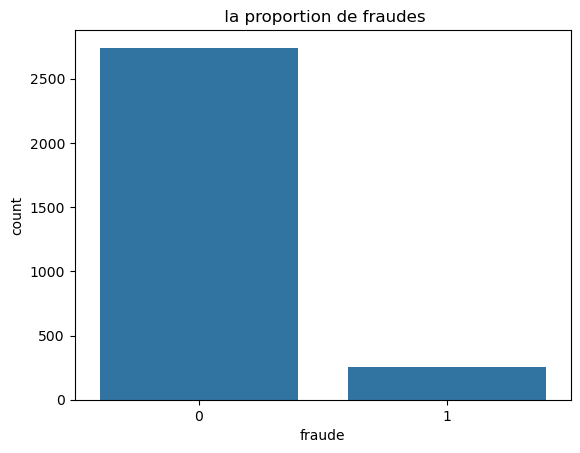

In [563]:
sns.countplot(data=df, x='fraude')

plt.title(' la proportion de fraudes')
plt.xlabel('fraude')
plt.show()

## le fichier est il equilibre ? Pourquoi est-ce important pour preparer les donnees?

##### Réponse : non ,  les classes sont **déséquilibrées**
##### le modèle sera incapable de détecter les fraudes

### 6. Repérez les identifiants et la colonne resultat_enquete. Expliquez pourquoi ces colonnes ne doivent
pas être incluses dans les variables préparées. À quel moment connait-on resultat_enquete?

####  la colonne **resultat_enquete** a le meme resultat aue la colonne **fraude** donc on va sauvgarder seulment la colonne fraude 
#### la colonne **id_client** sans signification statistique 
#### on connait resultat_enquete au moment apres une enquête donc après coup. Au moment de la  transaction cette information n'existe pas

In [564]:
df['resultat_enquete'] = df['resultat_enquete'].map({'fraude_confirmee': 1, 'aucune_fraude': 0})

In [565]:
df['resultat_enquete'].eq(df['fraude']).value_counts()

True    3000
Name: count, dtype: int64

# **Partie 2** — Préparer les données sans fuite

### 7. Après suppression des doublons, créez X (variables à préparer) et y (fraude). Retirez de X les
identifiants et resultat_enquete. Conservez y pour étudier le déséquilibre des classes.

In [566]:
df.dtypes

id_operation         object
id_client            object
montant_dh          float64
anciennete_mois     float64
nb_ops_24h          float64
heure                 int64
canal                object
appareil             object
region               object
international        object
resultat_enquete      int64
fraude                int64
dtype: object

In [567]:
y = df["fraude"]
X = df.drop(columns=["id_operation", "id_client", "resultat_enquete", "fraude"])

###  Avec train_test_split, créez deux groupes : 80 % des lignes comme groupe de référence et 20 %
comme groupe de vérification (stratify=y, random_state=42). Comparez les proportions de fraude.
Aucun classifieur ne sera entraîné.

In [568]:
from sklearn.model_selection import train_test_split

In [569]:
X_ref, X_ver, y_ref, y_ver = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

In [570]:
X_ref.shape



(2400, 8)

In [571]:
X_ver.shape

(600, 8)

In [572]:
y_ref.value_counts(normalize=True) *100

fraude
0    91.416667
1     8.583333
Name: proportion, dtype: float64

In [573]:
y_ver.value_counts(normalize=True) *100

fraude
0    91.333333
1     8.666667
Name: proportion, dtype: float64

### 9. Listez les variables numériques et catégorielles. Expliquez pourquoi les catégories comme canal et
region ne doivent pas être traitées comme des nombres ordinaires.

In [574]:
numerical_features = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]
categorical_features = [ "canal","appareil","region","international"]

#### Réponse : **canal, region** sont des étiquettes SANS ordre  pas une quantité #### Un codage numérique arbitraire ferait croire à un ordre ou à une distance.é.
 

### 10. Construisez un pipeline pour les nombres : remplacer les valeurs manquantes par la médiane,
puis appliquer StandardScaler. Calculez la médiane et l’échelle uniquement sur le groupe de référence.

In [575]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, RobustScaler, MinMaxScaler, OneHotEncoder)

In [576]:
pipe_numerical = Pipeline([
    ('imputer', SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [577]:
pipe_numerical.fit(X_ref[numerical_features]) 

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])

In [578]:

print("Médianes (réf.) :", pipe_numerical["imputer"].statistics_)
print("Moyennes (réf.) :", pipe_numerical["scaler"].mean_)
print("Écarts-types    :", pipe_numerical["scaler"].scale_)

Médianes (réf.) : [710.79  87.     3.    11.  ]
Moyennes (réf.) : [1020.672925     87.48333333    2.72083333   11.47      ]
Écarts-types    : [1327.6254132    49.48592112    1.64607593    6.99546996]


### 11. Construisez un pipeline catégoriel : imputation par la valeur la plus fréquente, puis OneHotEnco
der(handle_unknown="ignore").

In [579]:
pipe_categorical = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))])
 

### 12. Réunissez les deux pipelines avec ColumnTransformer. Transformez les groupes de référence et de
vérification. Comparez le nombre de lignes et de colonnes obtenues.

In [580]:
from sklearn.compose import ColumnTransformer

In [581]:
preprocessor = ColumnTransformer(
    [
        ('num', pipe_numerical, numerical_features),
        ('cat', pipe_categorical, categorical_features)
    ],
    sparse_threshold=0 
)

In [582]:
Xref_std = preprocessor.fit_transform(X_ref)   # fit sur la référence uniquement


In [583]:
Xver_std = preprocessor.transform(X_ver)       # transform seulement (pas de fit)


In [584]:
print("Référence    :", Xref_std.shape)
print("Vérification :", Xver_std.shape)

Référence    : (2400, 18)
Vérification : (600, 18)


 ### Même nombre de colonnes (mêmes paramètres), nombre de lignes différent (80 % / 20 %).

### 13. Remplacez StandardScaler par RobustScaler. Comparez la valeur transformée de montant_dh
pour une opération ordinaire et une opération au montant très élevé. Expliquez ce qui change

In [585]:
amount_imputer = SimpleImputer(strategy="median")


In [586]:
train_amount_imputed = amount_imputer.fit_transform(X_ref[["montant_dh"]])


In [587]:
test_amount_imputed = amount_imputer.transform(X_ver[["montant_dh"]])

In [588]:
std_amount = StandardScaler().fit(train_amount_imputed)


In [589]:
rob_amount = RobustScaler().fit(train_amount_imputed)


In [590]:
#Choisir une valeur ordinaire (médiane du train) et une valeur élevée (maximum du train)
ordinary_amount = float(np.nanmedian(X_ref["montant_dh"]))
extreme_amount = float(np.nanmax(X_ref["montant_dh"]))
comparison_values = np.array([[ordinary_amount], [extreme_amount]])
print("\nQ13 — Montants choisis :", ordinary_amount, "et", extreme_amount)
print(pd.DataFrame({
    "montant_initial": comparison_values.ravel(),
    "StandardScaler": std_amount.transform(comparison_values).ravel(),
    "RobustScaler": rob_amount.transform(comparison_values).ravel()
}))


Q13 — Montants choisis : 710.79 et 33281.23
   montant_initial  StandardScaler  RobustScaler
0           710.79       -0.233411      0.000000
1         33281.23       24.299442     39.892755


#### Explication : 
#### le StandardScaler compresse les montants ordinaires.
#### RobustScaler garde les montants ordinaires bien étalés et laisse le montant extrême ressortir avec une grande valeur.

### 14. Expliquez ce qui peut mal se passer si la médiane ou les paramètres de normalisation sont calculés
sur toutes les lignes, y compris le groupe de vérification.

In [591]:
# Si médiane / moyenne / écart-type sont calculés sur TOUTES les lignes,# le groupe de# vérification influence les paramètres : il ne joue plus le rôle de données jamai  vues. L'évaluation devient optimiste et ne reflète plus le comportement réel sur 
# nouvelles transactions (data leakage).
 

# **Partie 3** — Comparer les méthodes de mise à l’échelle

### 15. Sur le groupe de référence, calculez les quartiles Q1 et Q3 de montant_dh, puis l’écart interquartile
IQR = Q3 − Q1. Expliquez avec vos mots ce que mesure l’IQR.

In [592]:
X_ref["montant_dh"].isna().sum()

88

In [593]:
mont_ref = X_ref["montant_dh"].dropna()

In [594]:
Q1 = mont_ref.quantile(0.25)

In [595]:
Q3 = mont_ref.quantile(0.75)

In [596]:
IQR = Q3 - Q1

#### **L'écart interquartile** (IQR) mesure la dispersion des données au centre (50 % des valeurs). Il correspond à la différence entre le 75e percentile (Q3) et le 25e percentile (Q1).


### 16. Repérez les montants situés sous Q1 − 1,5 × IQR ou au-dessus de Q3 + 1,5 × IQR. Combien de
lignes sont concernées? Vérifiez quelques cas : sont-ils nécessairement des erreurs?

In [597]:
upper_whisker = Q3 + 1.5 * IQR
lower_whisker =  Q1 - 1.5 * IQR
mask = (mont_ref < lower_whisker) | (mont_ref  > upper_whisker )

In [598]:
mask.sum()

146

In [599]:
mask.head(5)

384     False
2064    False
625     False
267     False
2306    False
Name: montant_dh, dtype: bool

### Pas nécessairement des erreurs : ce peuvent être de gros achats légitimes ou des fraudes

### 17. Comparez deux choix : conserver les montants extrêmes ou les limiter à des seuils choisis sur le
groupe de référence. Tracez deux boxplots. Expliquez pourquoi il faut justifier ce choix.

In [600]:
mont_ref.mean()

1032.467776816609

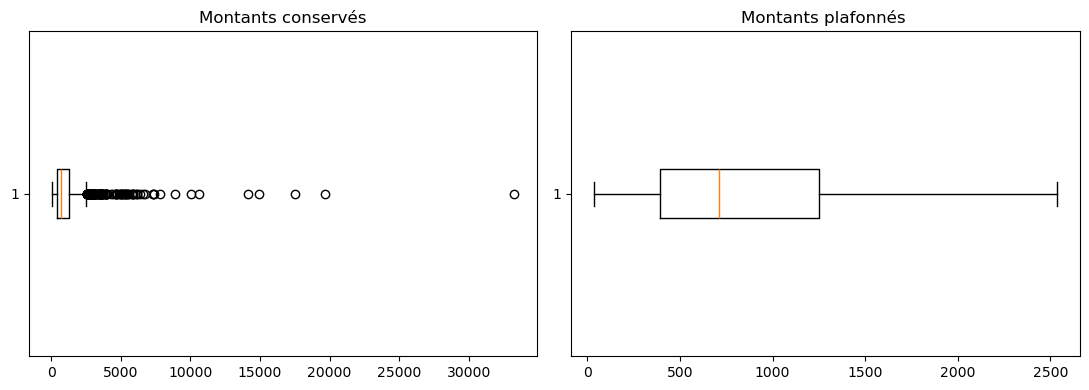

In [601]:
mont_clip = mont_ref.clip(lower=lower_whisker, upper=upper_whisker)  # seuils choisis sur la référence
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot(mont_ref, vert=False); 
ax[0].set_title("Montants conservés")
ax[1].boxplot(mont_clip, vert=False);
ax[1].set_title("Montants plafonnés ")
plt.tight_layout(); 
plt.show()

In [602]:
mont_clip.mean()

914.8335521193773

### 18. Pour montant_dh, appliquez séparément MinMaxScaler, StandardScaler et RobustScaler. Ajustez
chaque méthode sur le groupe de référence, puis transformez le groupe de vérification.

In [603]:
from sklearn.preprocessing import (StandardScaler, RobustScaler, MinMaxScaler)

In [604]:
scalers = {
    "MinMaxScaler": MinMaxScaler(),
    "StandardScaler": StandardScaler(),
    "RobustScaler": RobustScaler()
}
ref_amt = amount_imputer.fit_transform(X_ref[["montant_dh"]])
ver_amt = amount_imputer.transform(X_ver[["montant_dh"]])
scaled_test = {}
for name, scaler in scalers.items():
    scaler.fit(ref_amt)
    scaled_test[name] = scaler.transform(ver_amt).ravel()


### 19. Choisissez trois montants habituels et un montant très élevé. Présentez leurs valeurs avant et
après chaque transformation dans un tableau. Quelle méthode est la plus perturbée par les montants
extrêmes?

In [605]:
vals = np.array([Q1, mont_ref.median(),Q3, mont_ref.max()]).reshape(-1, 1)
tab = pd.DataFrame({"Montant": vals.ravel()})
for nom, sc in scalers.items():
    tab[nom] = sc.transform(vals).ravel()


In [606]:
tab.round(3)

,Montant,MinMaxScaler,StandardScaler,RobustScaler
0,393.095,0.011,-0.473,-0.389
1,710.790,0.020,-0.233,0.000
2,1249.878,0.037,0.173,0.660
3,33281.230,1.000,24.299,39.893


### Les montants habituels sont écrasés vers 0 par **MinMax** (le max extrême étire l'échelle) et par **Z-score** (moyenne et écart-type gonflés).
### **RobustScaler** est le moins perturbé 
## **MinMax** est le plus sensible aux extrêmes (utilise min et max).

### 20. Tracez trois histogrammes du montant transformé. Expliquez la différence : Min-Max utilise min
et max; Z-score utilise moyenne et écart-type; RobustScaler utilise médiane et IQR.

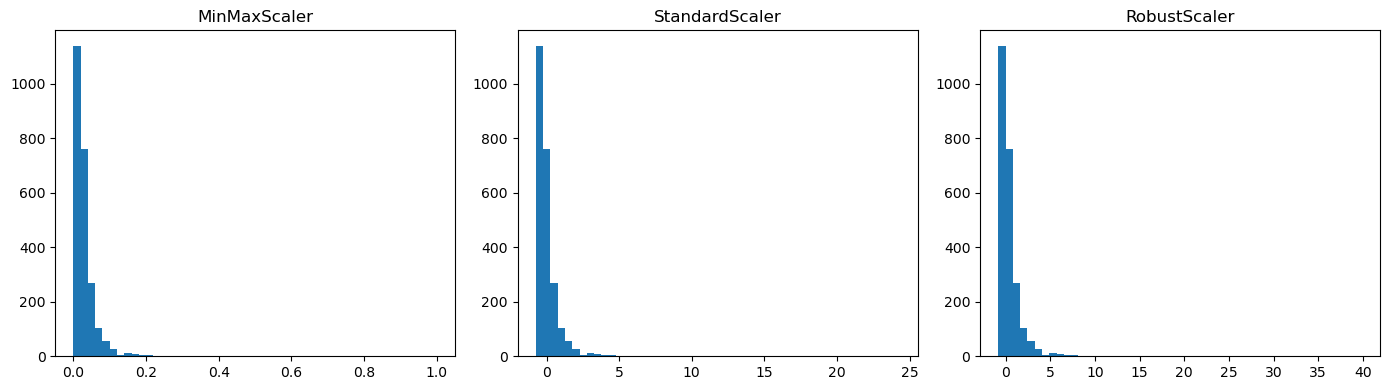

In [607]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, scaler) in zip(axes, scalers.items()):
    transformed = scaler.transform(ref_amt).ravel()
    ax.hist(transformed, bins=50)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 21. Une nouvelle transaction peut dépasser le maximum du groupe de référence. Avec Min-Max, sa
valeur transformée peut-elle dépasser 1? Vérifiez avec un petit exemple numérique et expliquez.

In [608]:
example = np.array([[100.0], [5000.0]])
example_scaler = MinMaxScaler().fit(example)
new_transaction = np.array([[6000.0]])
print(example_scaler.transform(new_transaction)[0, 0])


# Oui : le scaler garde min/max de la référence ; une valeur plus grande donne > 1
# (et une valeur plus petite que le min donnerait < 0).
 

1.2040816326530612


### Oui : le scaler garde min/max de la référence ; une valeur plus grande donne > 1
### (et une valeur plus petite que le min donnerait < 0).
 

# **Partie 4** — Préparer des classes déséquilibrées

### 22. Dans le groupe de référence, comptez les lignes de chaque classe (fraude = 0 et fraude = 1).
Calculez le rapport entre les deux classes.

In [609]:
df['fraude'].value_counts()

fraude
0    2742
1     258
Name: count, dtype: int64

In [610]:
y_ref.head(3)

384     0
2064    0
625     0
Name: fraude, dtype: int64

In [611]:
cnt0 = (y_ref == 0).sum()
cnt0

2194

In [612]:
cnt1 = (y_ref == 1).sum()
cnt1

206

In [613]:
rapport = cnt0 / cnt1
rapport

10.650485436893204

### 23. Appliquez RandomOverSampler uniquement au groupe de référence. Notez le nombre de lignes
de chaque classe avant et après. Les nouvelles lignes sont-elles des copies de lignes existantes?

In [614]:
from imblearn.over_sampling import RandomOverSampler, SMOTE, SMOTENC
from imblearn.under_sampling import RandomUnderSampler

In [615]:
# nombre de la classe avant 
y_ref.value_counts().sort_index()

fraude
0    2194
1     206
Name: count, dtype: int64

In [616]:
ros = RandomOverSampler(random_state=42)
X_ros, y_ros = ros.fit_resample(X_ref, y_ref)
print(y_ros.value_counts().sort_index())
# nombre de la classe apres


fraude
0    2194
1    2194
Name: count, dtype: int64


###  Les nouvelles lignes sont-elles des copies de lignes existantes? 
#### reponse :  **Oui**  , ce sont des copies exactes (tirage avec remise) de lignes de la classe minoritaire.

### 24. Reprenez le groupe de référence initial et appliquez RandomUnderSampler. Comptez les lignes
conservées et supprimées. Quel est le risque de cette méthode?

In [617]:
rus = RandomUnderSampler(random_state=42)
X_rus, y_rus = rus.fit_resample(X_ref, y_ref)
print(y_rus.value_counts().sort_index())

fraude
0    206
1    206
Name: count, dtype: int64


In [618]:
print("Conservées :", len(y_rus))
print( "Supprimées :", len(y_ref) - len(y_rus))


Conservées : 412
Supprimées : 1988


### Risque : on jette beaucoup d'opérations normales -> perte d'information utile.

### 25. Sur un petit exemple à deux variables numériques, illustrez SMOTE : comparez une valeur
réelle et une valeur synthétique construite entre deux observations de la classe minoritaire. Expliquez
pourquoi cette méthode ne fait pas une simple copie.

In [619]:
point_a = np.array([2.0, 4.0])
point_b = np.array([6.0, 8.0])
lambda_value = 0.25
synthetic_point = point_a + lambda_value * (point_b - point_a)
print("\nQ25 — Exemple SMOTE")
print("Observation A :", point_a)
print("Observation B :", point_b)
print("Point synthétique (lambda=0.25) :", synthetic_point)
print("SMOTE crée un point intermédiaire par interpolation entre observations minoritaires.")



Q25 — Exemple SMOTE
Observation A : [2. 4.]
Observation B : [6. 8.]
Point synthétique (lambda=0.25) : [3. 5.]
SMOTE crée un point intermédiaire par interpolation entre observations minoritaires.


In [620]:
A = np.array([2.0, 3.0]);
B = np.array([4.0, 7.0])   
lam = 0.5                                            # lam dans [0,1], tiré au hasard par SMOTE
synth = A + lam * (B - A)
print("A =", A, "| B =", B, "| point synthétique =", synth)

A = [2. 3.] | B = [4. 7.] | point synthétique = [3. 5.]


In [621]:

Xtoy = np.array([[2, 3], [4, 7], [3, 4], [10, 10], [11, 12], [9, 11], [10, 9], [12, 10]], float)
ytoy = np.array([1, 1, 0, 0, 0, 0, 0, 0])
Xs, ys = SMOTE(k_neighbors=1, random_state=42).fit_resample(Xtoy, ytoy)
print("Points synthétiques SMOTE :\n", Xs[len(Xtoy):])

Points synthétiques SMOTE :
 [[3.46398788 5.92797577]
 [2.80268303 4.60536606]
 [2.31203728 3.62407456]
 [2.31198904 3.62397808]]


### Le point est une interpolation sur le segment entre deux fraudes voisines : nouvelle valeur, pas une copie.

### 26. Pourquoi faut-il faire attention lorsque SMOTE est appliqué à des catégories codées en one-hot?
Nommez une méthode conçue pour les données mêlant nombres et catégories.

### SMOTE interpole : entre deux lignes one-hot on obtient 0.37 ou 0.5 au lieu de 0/1,
### ce qui n'a pas de sens pour une catégorie (modalité à moitié "mobile" ?).
### Méthode adaptée aux données mixtes : SMOTENC (ou SMOTEN pour tout-catégoriel).

### 27. Présentez dans un tableau les effectifs des classes avant rééquilibrage, après suréchantillonnage et
après sous-échantillonnage. Le groupe de vérification doit-il changer? Justifiez.

In [622]:
tab_cl = pd.DataFrame({
    "Avant": y_ref.value_counts(),
    "Sur-échantillonnage": y_ros.value_counts(),
    "Sous-échantillonnage": y_rus.value_counts()})
print(tab_cl)

print("Vérification :", y_ver.value_counts())
 

        Avant  Sur-échantillonnage  Sous-échantillonnage
fraude                                                  
0        2194                 2194                   206
1         206                 2194                   206
Vérification : fraude
0    548
1     52
Name: count, dtype: int64


### Le groupe de vérification NE DOIT PAS changer : il doit rester représentatif de la réalité (classes rares) pour évaluer honnêtement 
### le rééquilibrage est un outil de préparation du groupe de référence seulement.

# **Partie 5** — Vérifier et enregistrer les données préparées

### 28. Créez une version finale de ColumnTransformer : médiane et RobustScaler pour les nombres,
modalité fréquente et OneHotEncoder(handle_unknown="ignore") pour les catégories.

In [623]:
final_prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", RobustScaler())]), numerical_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)],
    sparse_threshold=0)
 

### 29. Calculez les paramètres du transformateur final sur le groupe de référence uniquement. Appliquez
ensuite ce même transformateur aux deux groupes. Vérifiez le nombre de colonnes et l’absence de
valeurs manquantes dans les résultats.

In [624]:
Xref_f = final_prep.fit_transform(X_ref)
Xver_f = final_prep.transform(X_ver)

In [625]:
print("Colonnes réf :", Xref_f.shape[1])
print("Colonnes vérif:", Xver_f.shape[1])
print("NaN réf :", int(np.isnan(Xref_f).sum()))
print("NaN vérif :", int(np.isnan(Xver_f).sum()))

Colonnes réf : 18
Colonnes vérif: 18
NaN réf : 0
NaN vérif : 0


### 30. Simulez une nouvelle catégorie de canal inconnue du groupe de référence. Vérifiez que OneHotEn
coder peut transformer cette ligne sans erreur. Expliquez le rôle de handle_unknown="ignore".

In [626]:
nouvelle = X_ref.iloc[[0]].copy()
nouvelle["canal"] = "canal_inconnu"
out = final_prep.transform(nouvelle)
print("Dimension de la ligne transformée :", out.shape)


Dimension de la ligne transformée : (1, 18)


#### handle_unknown="ignore" : une modalité jamais vue donne des 0 sur toutes les colonnes de cette variable au lieu de lever une erreur.
####  Le pipeline reste utilisable en production.

### 31. Enregistrez le transformateur préparé avec joblib, puis rechargez-le. Vérifiez qu’il donne les mêmes
valeurs pour un petit échantillon, sans recalculer les médianes ni les échelles.

In [627]:
import joblib

In [628]:
joblib.dump(final_prep, "preprocesseur_TP2.joblib")
rechargé = joblib.load("preprocesseur_TP2.joblib")
echantillon = X_ver.head(10)
echantillon

,montant_dh,anciennete_mois,nb_ops_24h,heure,canal,appareil,region,international
2780,795.50,62.0,1.0,15,telephone,ordinateur,Draa-Tafilalet,oui
34,1144.86,106.0,5.0,3,telephone,ordinateur,Marrakech-Safi,non
2657,259.10,70.0,2.0,1,site_web,mobile,Marrakech-Safi,non
2377,347.80,139.0,5.0,23,telephone,mobile,Casablanca-Settat,non
2883,451.36,99.0,2.0,23,NaN,NaN,Souss-Massa,oui
1978,574.89,167.0,5.0,19,agence,ordinateur,Casablanca-Settat,non
240,1801.63,91.0,3.0,4,site_web,ordinateur,Souss-Massa,non
131,498.07,52.0,1.0,0,application,mobile,Marrakech-Safi,oui
2508,764.14,5.0,6.0,2,site_web,mobile,Draa-Tafilalet,non
403,485.04,109.0,2.0,2,site_web,mobile,Marrakech-Safi,non


In [629]:
print("Mêmes valeurs :", np.allclose(final_prep.transform(echantillon),rechargé.transform(echantillon)))
 

Mêmes valeurs : True


### 32. Faites un bilan de votre travail : nombre de doublons retirés, valeurs manquantes traitées,
valeurs extrêmes observées, méthodes de transformation choisies et effet du rééquilibrage. Justifiez
vos principaux choix

In [630]:
missing_handled = int(df[ X.columns ].isna().sum().sum())

In [631]:
print("Doublons id_operation retirés :", duplicate_count)
print("Valeurs manquantes présentes dans X après dédoublonnage :", missing_handled)
print("Valeurs extrêmes montant_dh dans le groupe de référence :", int(mask.sum()))



Doublons id_operation retirés : 45
Valeurs manquantes présentes dans X après dédoublonnage : 673
Valeurs extrêmes montant_dh dans le groupe de référence : 146


In [632]:
print("Méthodes retenues : médiane + RobustScaler pour les variables numériques ;")


Méthodes retenues : médiane + RobustScaler pour les variables numériques ;


In [633]:
print("mode + OneHotEncoder(handle_unknown='ignore') pour les variables catégorielles.")


mode + OneHotEncoder(handle_unknown='ignore') pour les variables catégorielles.


In [634]:
print("Rééquilibrage étudié sur le groupe de référence uniquement ; groupe de vérification conservé sans modification.")


Rééquilibrage étudié sur le groupe de référence uniquement ; groupe de vérification conservé sans modification.


# **Travail complémentaire**ons.

#### • Bonus A : comparez l’imputation par la moyenne et par la médiane sur la variable montant_dh.
#####  Quelle méthode résiste le mieux à un montant très élevé?


In [635]:
print(" moyenne vs médiane ===")

s_ext = pd.concat([mont_ref, pd.Series([mont_ref.max() * 50])])
print(f"Sans extrême : moyenne={mont_ref.mean():.1f} médiane={mont_ref.median():.1f}")
print(f"Avec extrême : moyenne={s_ext.mean():.1f} médiane={s_ext.median():.1f}")


 moyenne vs médiane ===
Sans extrême : moyenne=1032.5 médiane=710.8
Avec extrême : moyenne=1751.5 médiane=711.3


In [636]:
print("Moyenne train :", X_ref["montant_dh"].mean())
print("Médiane train :", X_ref["montant_dh"].median())
print("La médiane est généralement moins sensible à un montant extrême que la moyenne.")



Moyenne train : 1032.467776816609
Médiane train : 710.79
La médiane est généralement moins sensible à un montant extrême que la moyenne.


In [637]:
numerical_features = ["montant_dh", "anciennete_mois", "nb_ops_24h", "heure"]
categorical_features = [ "canal","appareil","region","international"]

#### • Bonus B : testez un rééquilibrage par SMOTENC sur un exemple mélangeant variables numériques et catégorielles; examinez les catégories obtenues et expliquez vos précautions.

In [638]:
Xb = X_ref[numerical_features + categorical_features].copy()
Xb[numerical_features] = SimpleImputer(strategy="median").fit_transform(Xb[numerical_features])
Xb[categorical_features] = SimpleImputer(strategy="most_frequent").fit_transform(Xb[categorical_features])
cat_idx = [Xb.columns.get_loc(c) for c in categorical_features]
sm = SMOTENC(categorical_features=cat_idx, random_state=42)
Xb_res, yb_res = sm.fit_resample(Xb, y_ref)
print("Classes après SMOTENC :", pd.Series(yb_res).value_counts().to_dict())
print("Catégories de canal :", sorted(Xb_res["canal"].unique()))
# Précautions : appliquer sur la référence seulement, vérifier que les catégories
# générées existent déjà (SMOTENC prend la modalité majoritaire des voisins).
 

Classes après SMOTENC : {0: 2194, 1: 2194}
Catégories de canal : ['agence', 'application', 'site_web', 'telephone']
